# Tópico 15 - Função de Transferência Discreta

## Visão Geral e Objetivos
Neste notebook, investigamos a **Função de Transferência Discreta $H(z)$** e sua relação com **Equações de Diferenças Finitas** em sistemas discretos LTI. Os principais objetivos são:
1. **Modelagem no Domínio-$z$**: Obter a função de transferência $H(z) = \frac{Y(z)}{X(z)} = \frac{1}{1 - a z^{-1}} = \frac{z}{z - a}$ a partir da equação de diferenças autorregressiva $y[n] = a y[n-1] + x[n]$.
2. **Resposta ao Impulso $h[n]$**: Simular e comparar a resposta ao impulso $h[n] = a^n u[n]$ para diferentes localizações de polo:
   - Polos reais positivos internos: $a = 0.5$ e $a = 0.9$ (Decaimento monotônico).
   - Polo real negativo interno: $a = -0.8$ (Decaimento com oscilação sinal-alternada).
   - Polo externo ao círculo unitário: $a = 1.1$ (Resposta divergente / instável).
3. **Mapeamento no Plano-$z$**: Representar a posição de cada polo em relação ao círculo unitário ($|z| = 1$) e relacioná-la com a estabilidade BIBO.
4. **Gerenciamento de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação.

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Simulação da Resposta ao Impulso para Diferentes Polos ($a$)

A equação de diferenças $y[n] - a y[n-1] = x[n]$ possui função de transferência:
$$H(z) = \frac{1}{1 - a z^{-1}} = \frac{z}{z - a}$$

A resposta ao impulso analítica é $h[n] = a^n u[n]$.
Abaixo, simulamos computacionalmente a resposta $h[n]$ para 20 amostras ($n = 0, 1, \dots, 19$) variando $a \in \{0.5, 0.9, -0.8, 1.1\}$.

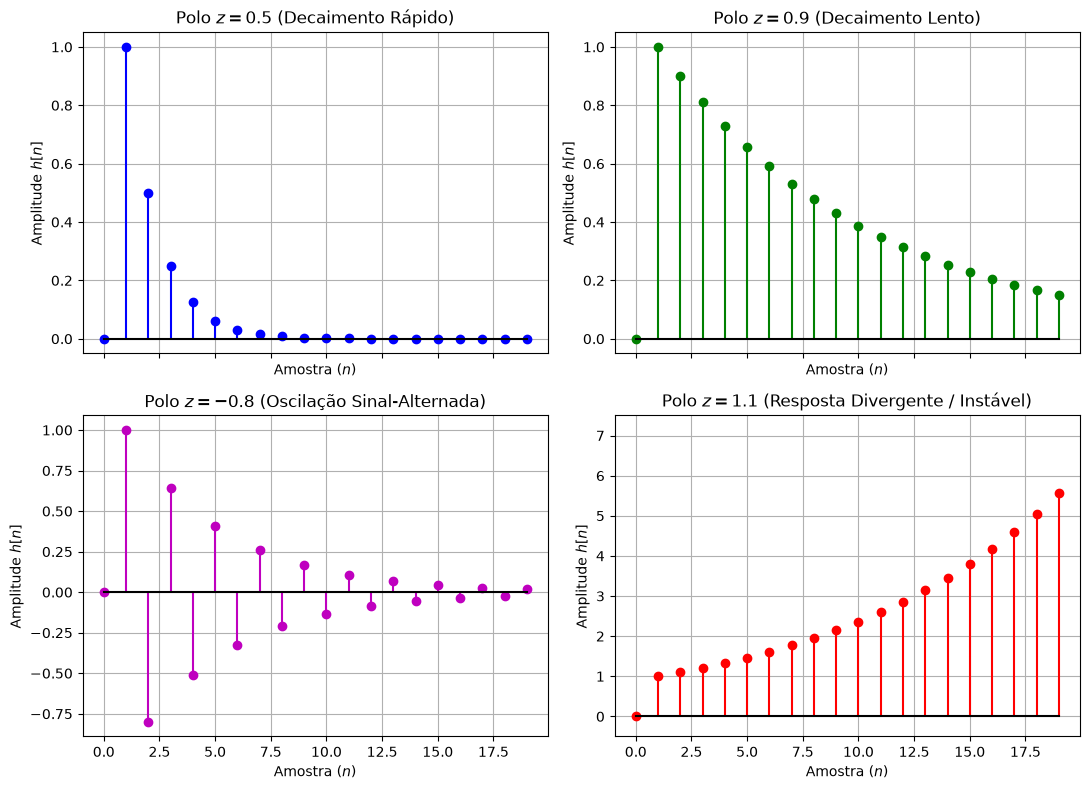

In [13]:
# Número de amostras para simulação temporal
N_amostras = 20
n = np.arange(N_amostras)

# Sinal de entrada: Impulso Unitário delta[n]
x_imp = np.zeros(N_amostras)
x_imp[0] = 1.0

# Polos sugeridos no roteiro: 0.5, 0.9, -0.8, 1.1
polos = [0.5, 0.9, -0.8, 1.1]
titulos_polos = [
    r'Polo $z = 0.5$ (Decaimento Rápido)',
    r'Polo $z = 0.9$ (Decaimento Lento)',
    r'Polo $z = -0.8$ (Oscilação Sinal-Alternada)',
    r'Polo $z = 1.1$ (Resposta Divergente / Instável)'
]
cores = ['b', 'g', 'm', 'r']

fig1, axs1 = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
axs1 = axs1.flatten()

for idx, a_val in enumerate(polos):
    # Coeficientes da equação de diferenças: y[n] - a*y[n-1] = x[n]
    b = [1.0]
    a_coef = [1.0, -a_val]
    
    # Sistema LTI discreto
    sys = signal.dlti(b, a_coef)
    t_out, h_n = signal.dlsim(sys, x_imp)
    h_n = np.squeeze(h_n)
    
    axs1[idx].stem(n, h_n, linefmt=f'{cores[idx]}-', markerfmt=f'{cores[idx]}o', basefmt='k-')
    axs1[idx].set_title(titulos_polos[idx])
    axs1[idx].set_xlabel('Amostra ($n$)')
    axs1[idx].set_ylabel('Amplitude $h[n]$')
    axs1[idx].grid(True)
    if a_val == 1.1:
        axs1[idx].set_ylim(-0.5, 7.5)

plt.tight_layout()
fig1.savefig("grafico_funcao_transferencia_discreta_tempo.png")
plt.show()

## 2. Mapeamento de Polos e Zeros no Plano Complexo $z$

Plotamos a localização de polos ($\times$) e zeros ($\circ$) para cada uma das quatro configurações de sistema discreto, comparando a posição do polo com a fronteira do **círculo unitário** ($|z| = 1$).

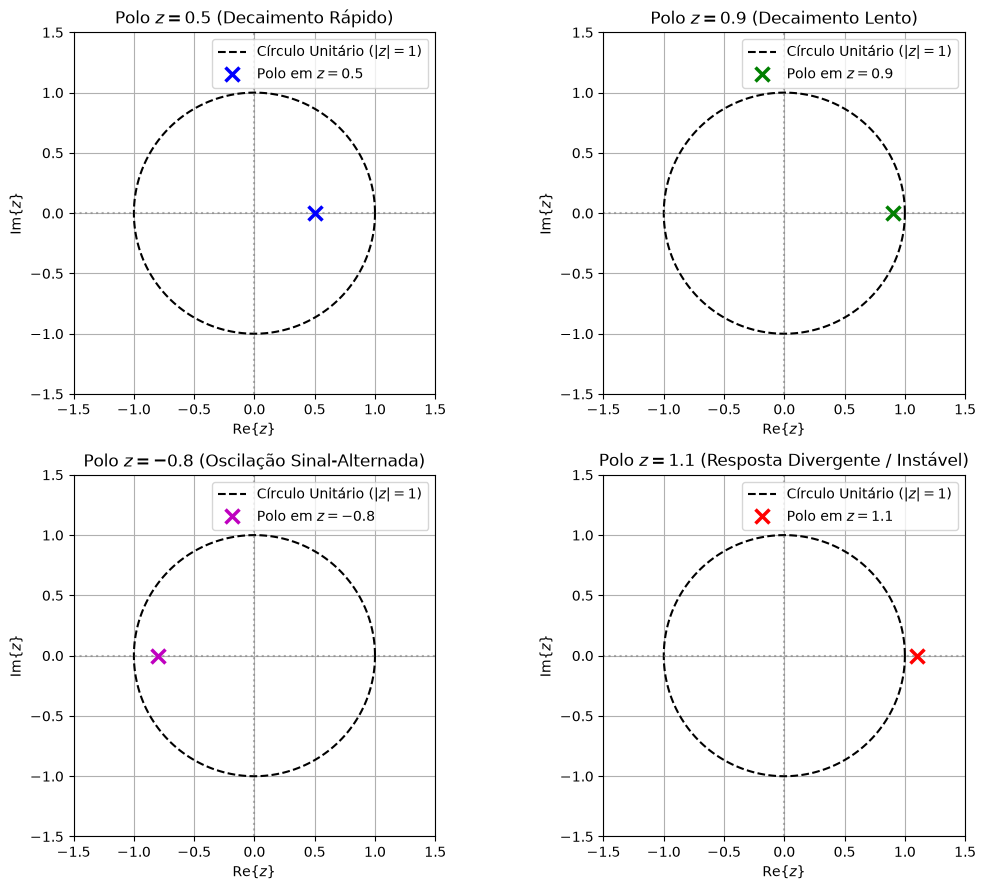

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fig2, axs2 = plt.subplots(2, 2, figsize=(11, 9))
axs2 = axs2.flatten()

theta = np.linspace(0, 2 * np.pi, 200)

polos = [0.5, 0.9, -0.8, 1.1]
titulos_polos = [
    r'Polo $z = 0.5$ (Decaimento Rápido)',
    r'Polo $z = 0.9$ (Decaimento Lento)',
    r'Polo $z = -0.8$ (Oscilação Sinal-Alternada)',
    r'Polo $z = 1.1$ (Resposta Divergente / Instável)'
]
cores = ['b', 'g', 'm', 'r']

for idx, a_val in enumerate(polos):
    b = [1.0]
    a_coef = [1.0, -a_val]
    sys = signal.dlti(b, a_coef)
    
    polos_sys = sys.poles
    zeros_sys = sys.zeros
    
    # Desenho do Círculo Unitário (|z| = 1)
    axs2[idx].plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
    axs2[idx].axhline(0, color='gray', linestyle=':', alpha=0.6)
    axs2[idx].axvline(0, color='gray', linestyle=':', alpha=0.6)
    
    # Plotar o Polo com 'X'
    axs2[idx].plot(np.real(polos_sys), np.imag(polos_sys), 'x', color=cores[idx], markersize=10, markeredgewidth=2.5, label=f'Polo em $z = {a_val}$')
    if len(zeros_sys) > 0:
        axs2[idx].plot(np.real(zeros_sys), np.imag(zeros_sys), 'o', color=cores[idx], markersize=8, markerfacecolor='none', markeredgewidth=2, label='Zeros')
        
    axs2[idx].set_title(titulos_polos[idx])
    axs2[idx].set_xlabel(r'$\text{Re}\{z\}$')
    axs2[idx].set_ylabel(r'$\text{Im}\{z\}$')
    axs2[idx].set_xlim(-1.5, 1.5)
    axs2[idx].set_ylim(-1.5, 1.5)
    axs2[idx].set_aspect('equal')
    axs2[idx].grid(True)
    axs2[idx].legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_funcao_transferencia_discreta_plano_z.png")
plt.show()

## 3. Síntese dos Resultados
- **Taxa de Amortecimento**: Polos situados dentro do círculo unitário ($|z| < 1$) geram respostas ao impulso que tendem assintoticamente a zero ($h[n] \rightarrow 0$). Quanto mais próximo de $1$ for o módulo do polo ($a = 0.9$), mais lenta é a taxa de decaimento.
- **Oscilação Alternada**: Polos no eixo real negativo ($a = -0.8$) produzem oscilações sinal-alternadas a cada amostra ($(-0.8)^n$), conservando o envelope atenuado.
- **Instabilidade**: O polo em $z = 1.1$ localiza-se fora do círculo unitário ($|z| > 1$). Sua resposta ao impulso cresce de forma exponencial divergente ($1.1^n \rightarrow \infty$), tornando o sistema BIBO instável.